In [1]:
# ============================================================
# Section 0: Import Libraries & Load Data
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"figure.dpi": 150, "font.size": 11})

df = pd.read_csv("AI_SocialMedia_Student_Health_Dataset_clean.csv")
df = df.drop(columns=["Student_ID"])

# Variable groups
NUM_FEATURES = [
    "Age", "Daily_Social_Media_Hours", "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours", "Physical_Activity_Hours", "Mental_Health_Score",
    "Physical_Health_Score", "Social_Isolation_Score", "Academic_Performance_Score"
]
CAT_FEATURES  = ["Gender", "Education_Level", "Burnout_Level"]
BURNOUT_ORDER = ["Low", "Moderate", "High", "Severe"]
BURNOUT_PAL   = {"Low": "#4CAF50", "Moderate": "#FFC107",
                 "High": "#FF5722", "Severe": "#B71C1C"}

print(f"Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Missing values: {df.isnull().sum().sum()}")

Dataset loaded: 15,000 rows × 13 columns
Missing values: 0


In [2]:
# ============================================================
# Section 1: Descriptive Statistics
# ============================================================

print("=" * 60)
print("Descriptive Statistics — Numerical Features")
print("=" * 60)
df[NUM_FEATURES].describe().round(2)

Descriptive Statistics — Numerical Features


,Age,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score,Social_Isolation_Score,Academic_Performance_Score
count,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00,15000.00
mean,19.04,4.54,2.58,6.54,1.25,72.51,88.02,4.31,78.31
std,3.77,2.40,1.68,1.27,1.04,9.25,9.68,1.16,11.54
min,13.00,0.00,0.00,2.00,0.00,32.56,48.03,0.97,23.99
25%,16.00,2.83,1.31,5.68,0.31,66.78,81.52,3.47,70.53
50%,19.00,4.50,2.51,6.55,1.13,73.76,89.47,4.28,78.59
75%,22.00,6.18,3.74,7.41,1.95,79.58,97.16,5.12,86.70
max,25.00,14.00,9.50,11.15,5.00,91.76,99.98,8.41,99.98


In [3]:
# ============================================================
# Section 1b: Categorical Value Counts
# ============================================================

for col in CAT_FEATURES:
    vc = df[col].value_counts()
    print(f"\n{col}:")
    for val, cnt in vc.items():
        print(f"  {val:<15} {cnt:>6}  ({cnt/len(df)*100:.1f}%)")


Gender:
  Male              7265  (48.4%)
  Female            7143  (47.6%)
  Non-binary         592  (3.9%)

Education_Level:
  High School       5693  (38.0%)
  University        4710  (31.4%)
  College           4597  (30.6%)

Burnout_Level:
  Low               9000  (60.0%)
  Moderate          4200  (28.0%)
  High              1350  (9.0%)
  Severe             450  (3.0%)


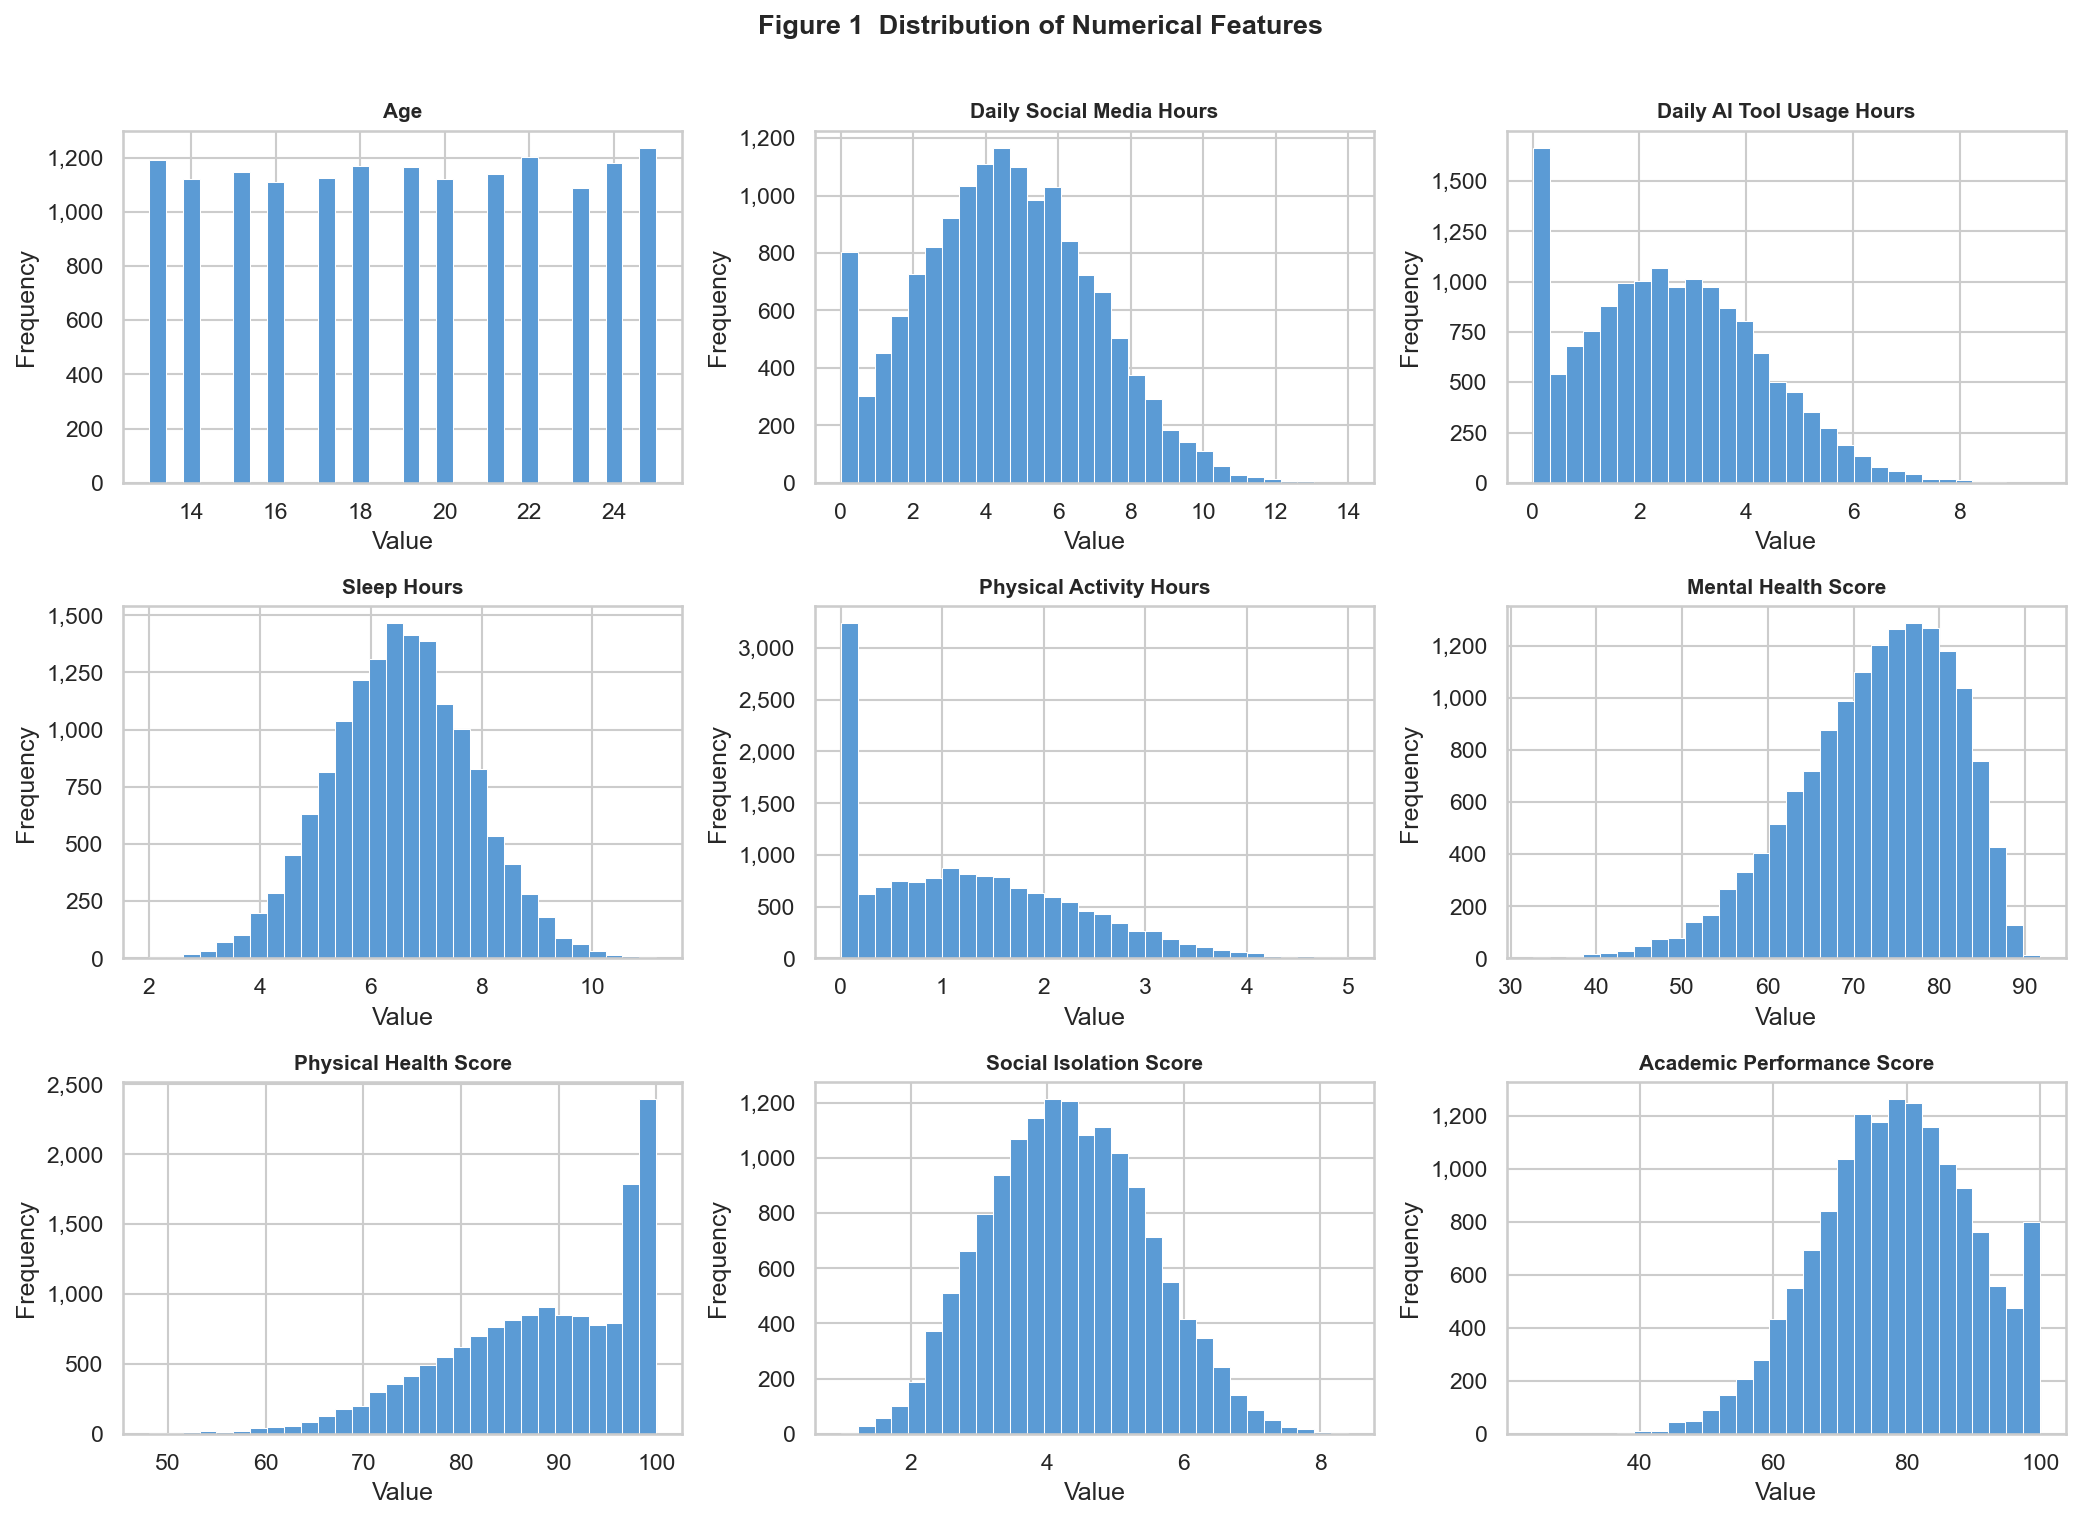

In [4]:
# ============================================================
# Figure 1: Histograms — Distribution of Numerical Features
# ============================================================

fig, axes = plt.subplots(3, 3, figsize=(14, 10))
axes = axes.flatten()

for i, col in enumerate(NUM_FEATURES):
    axes[i].hist(df[col], bins=30, color="#5B9BD5", edgecolor="white", linewidth=0.5)
    axes[i].set_title(col.replace("_", " "), fontsize=10, fontweight="bold")
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")
    axes[i].yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, _: f"{int(x):,}")
    )

plt.suptitle("Figure 1  Distribution of Numerical Features",
             fontsize=13, fontweight="bold", y=1.01)
plt.tight_layout()
plt.savefig("fig1_histograms.png", bbox_inches="tight")
plt.show()

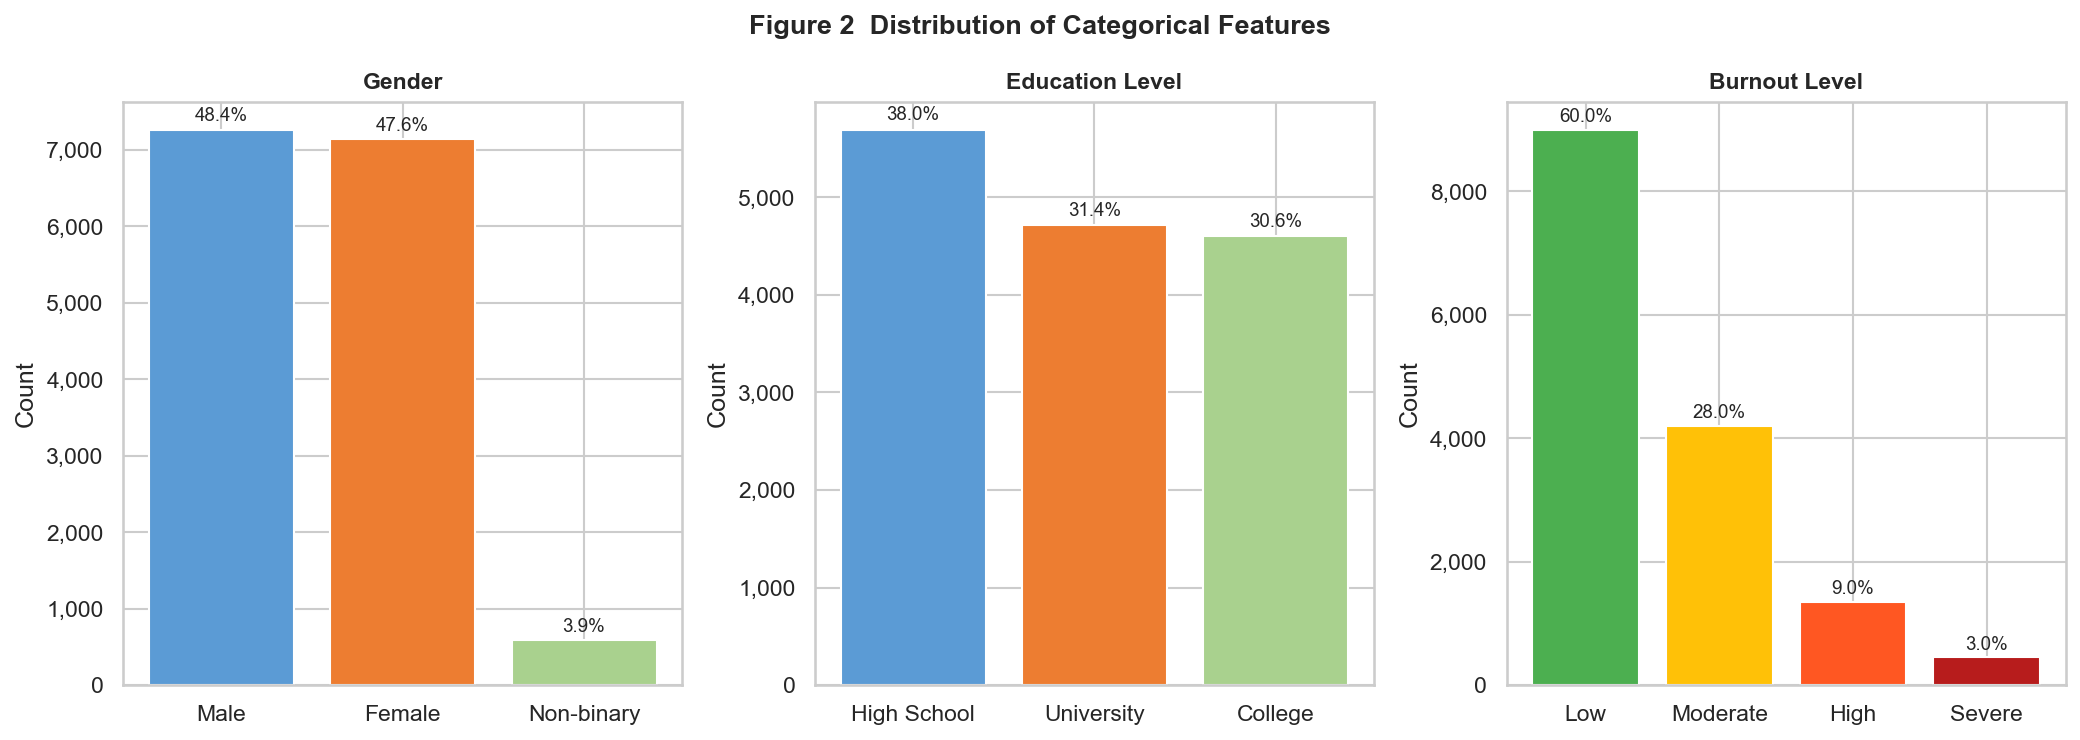

In [5]:
# ============================================================
# Figure 2: Bar Charts — Categorical Variable Distributions
# ============================================================

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
color_sets = [
    ["#5B9BD5", "#ED7D31", "#A9D18E"],
    ["#5B9BD5", "#ED7D31", "#A9D18E"],
    [BURNOUT_PAL[b] for b in BURNOUT_ORDER],
]

for i, col in enumerate(CAT_FEATURES):
    order  = BURNOUT_ORDER if col == "Burnout_Level" else df[col].value_counts().index.tolist()
    counts = df[col].value_counts().reindex(order)
    bars   = axes[i].bar(order, counts.values, color=color_sets[i], edgecolor="white")

    axes[i].set_title(col.replace("_", " "), fontsize=11, fontweight="bold")
    axes[i].set_ylabel("Count")
    axes[i].yaxis.set_major_formatter(
        ticker.FuncFormatter(lambda x, _: f"{int(x):,}")
    )
    for bar, val in zip(bars, counts.values):
        axes[i].text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 60,
            f"{val/len(df)*100:.1f}%",
            ha="center", va="bottom", fontsize=9
        )

plt.suptitle("Figure 2  Distribution of Categorical Features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig2_categorical_distribution.png", bbox_inches="tight")
plt.show()

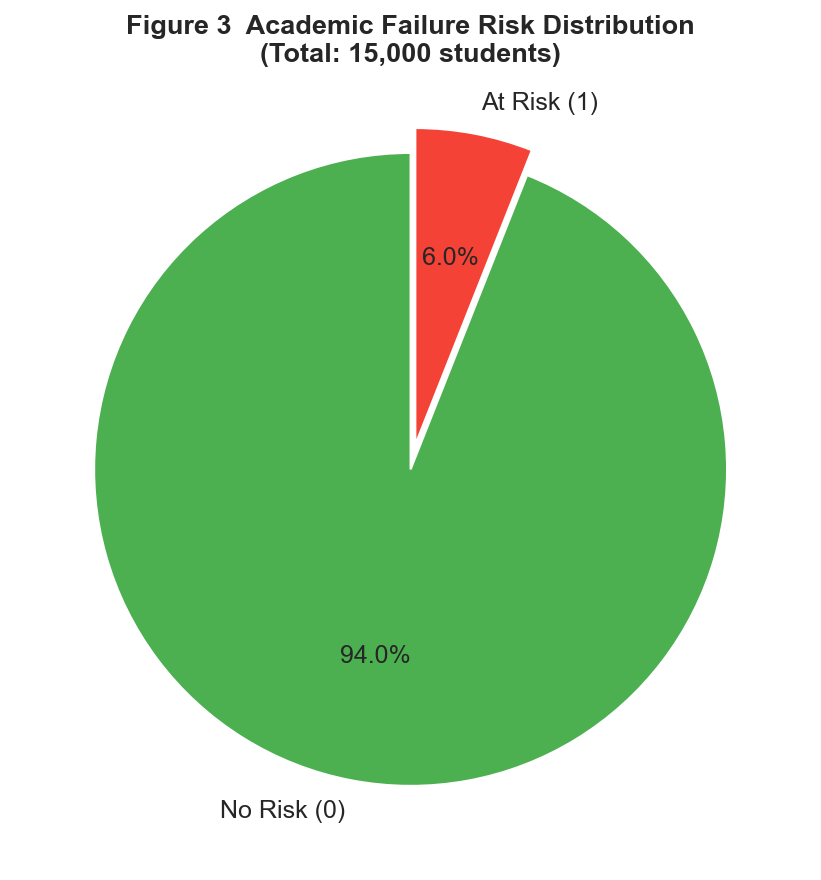

In [6]:
# ============================================================
# Figure 3: Pie Chart — Academic Failure Risk
# ============================================================

counts_risk = df["Academic_Failure_Risk"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    counts_risk.values,
    labels=["No Risk (0)", "At Risk (1)"],
    colors=["#4CAF50", "#F44336"],
    autopct="%1.1f%%",
    startangle=90,
    explode=(0, 0.08),
    textprops={"fontsize": 12}
)
ax.set_title(
    f"Figure 3  Academic Failure Risk Distribution\n(Total: {len(df):,} students)",
    fontsize=13, fontweight="bold"
)
plt.tight_layout()
plt.savefig("fig3_failure_risk_pie.png", bbox_inches="tight")
plt.show()

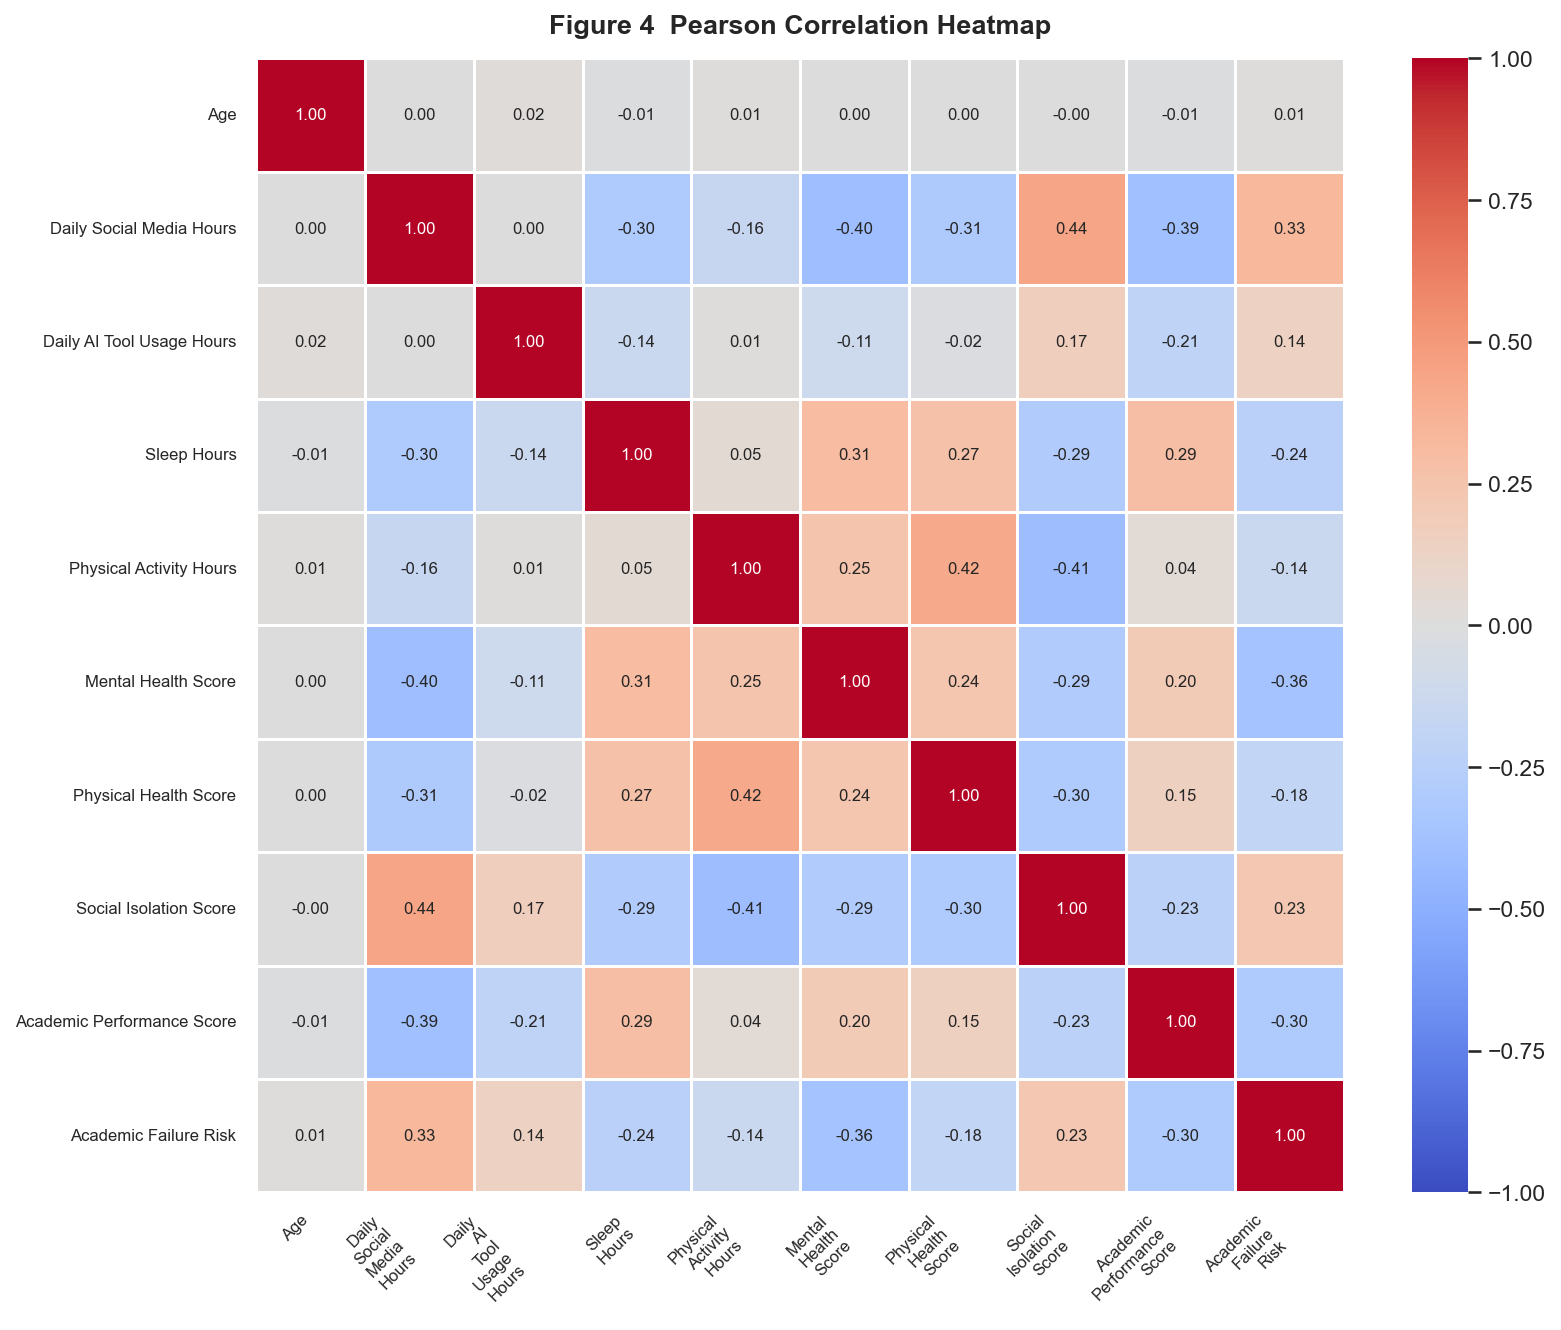

In [7]:
# ============================================================
# Figure 4: Pearson Correlation Heatmap
# ============================================================

corr_cols   = NUM_FEATURES + ["Academic_Failure_Risk"]
corr_matrix = df[corr_cols].corr(method="pearson").round(2)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr_matrix,
    annot=True, fmt=".2f", cmap="coolwarm",
    center=0, vmin=-1, vmax=1,
    linewidths=0.5, annot_kws={"size": 8},
    ax=ax
)
ax.set_xticklabels(
    [c.replace("_", "\n") for c in corr_matrix.columns],
    fontsize=8, rotation=45, ha="right"
)
ax.set_yticklabels(
    [c.replace("_", " ") for c in corr_matrix.index],
    fontsize=8, rotation=0
)
ax.set_title("Figure 4  Pearson Correlation Heatmap",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("fig4_correlation_heatmap.png", bbox_inches="tight")
plt.show()

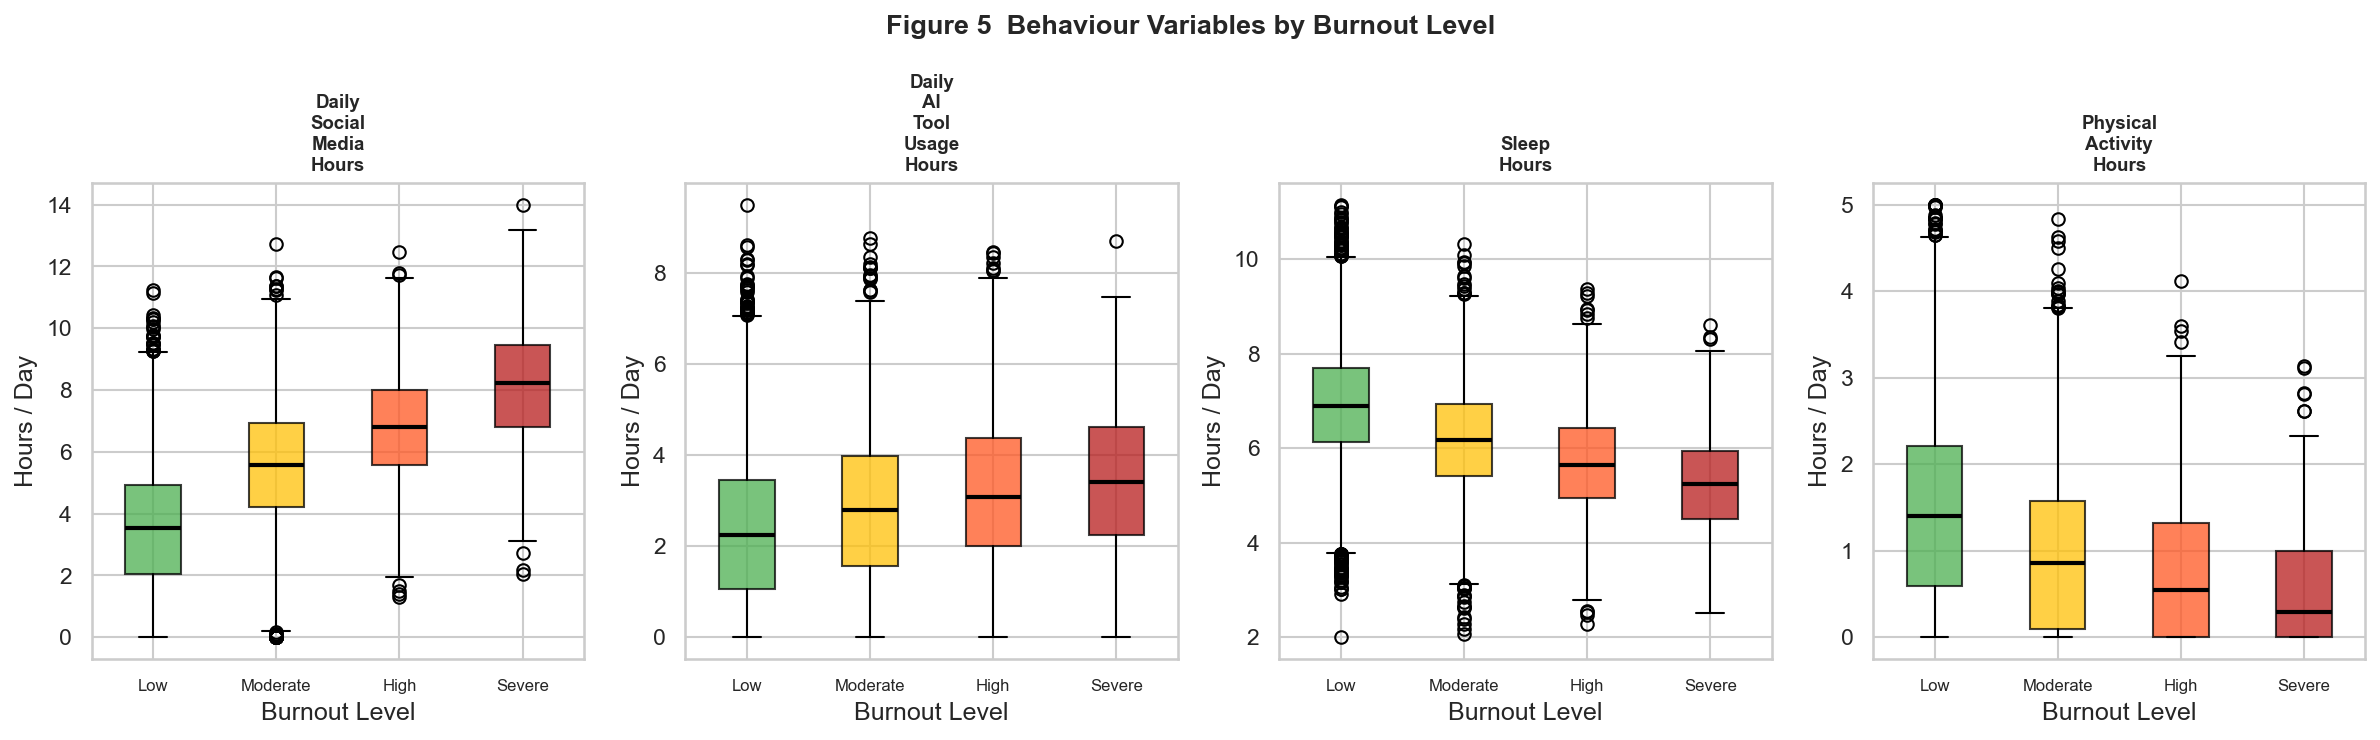

In [9]:
# ============================================================
# Figure 5: Boxplots — Behaviour Variables by Burnout Level
# ============================================================

behavior_vars = [
    "Daily_Social_Media_Hours", "Daily_AI_Tool_Usage_Hours",
    "Sleep_Hours", "Physical_Activity_Hours"
]

fig, axes = plt.subplots(1, 4, figsize=(16, 5))

for i, col in enumerate(behavior_vars):
    data_groups = [df[df["Burnout_Level"] == lvl][col].values for lvl in BURNOUT_ORDER]
    bp = axes[i].boxplot(
        data_groups, tick_labels=BURNOUT_ORDER, patch_artist=True,
        medianprops={"color": "black", "linewidth": 2}
    )
    for patch, lvl in zip(bp["boxes"], BURNOUT_ORDER):
        patch.set_facecolor(BURNOUT_PAL[lvl])
        patch.set_alpha(0.75)

    axes[i].set_title(col.replace("_", "\n"), fontsize=9, fontweight="bold")
    axes[i].set_xlabel("Burnout Level")
    axes[i].set_ylabel("Hours / Day")
    axes[i].tick_params(axis="x", labelsize=8)

plt.suptitle("Figure 5  Behaviour Variables by Burnout Level",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fig5_boxplot_burnout.png", bbox_inches="tight")
plt.show()

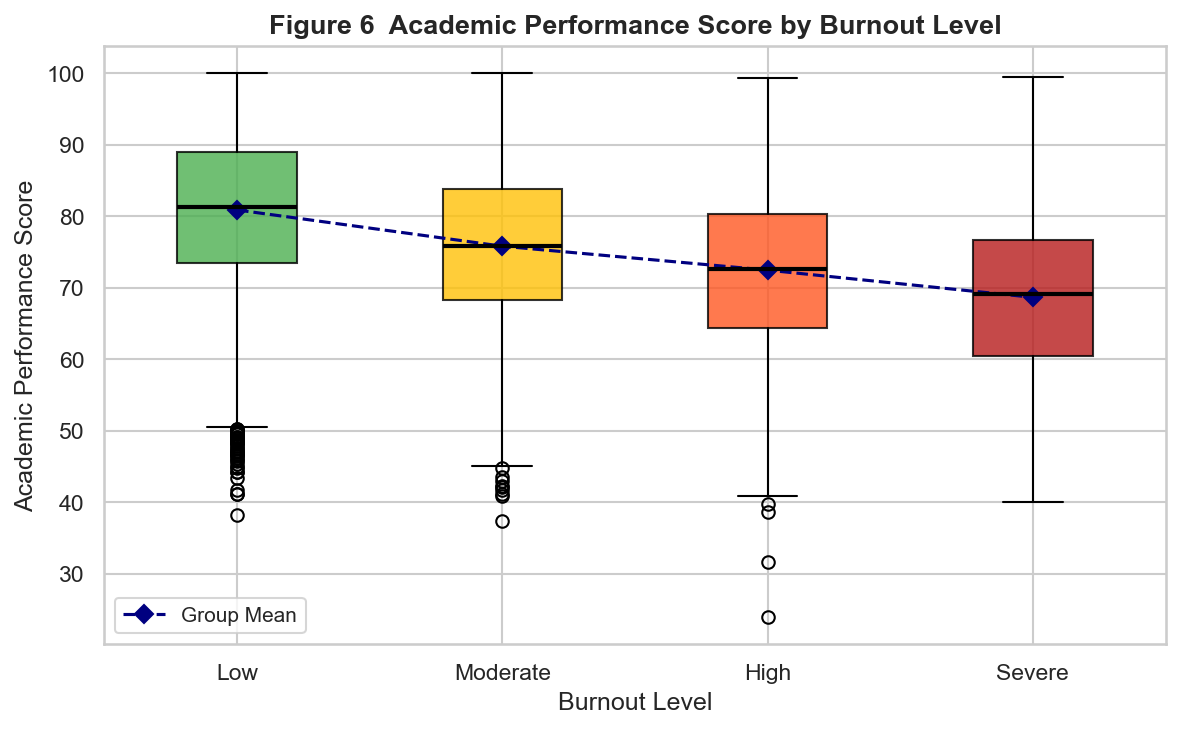

In [10]:
# ============================================================
# Figure 6: Boxplot — Academic Performance by Burnout Level
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))
data_groups = [
    df[df["Burnout_Level"] == lvl]["Academic_Performance_Score"].values
    for lvl in BURNOUT_ORDER
]
bp = ax.boxplot(
    data_groups, tick_labels=BURNOUT_ORDER, patch_artist=True,
    medianprops={"color": "black", "linewidth": 2}
)
for patch, lvl in zip(bp["boxes"], BURNOUT_ORDER):
    patch.set_facecolor(BURNOUT_PAL[lvl])
    patch.set_alpha(0.8)

means = [df[df["Burnout_Level"] == lvl]["Academic_Performance_Score"].mean()
         for lvl in BURNOUT_ORDER]
ax.plot(range(1, 5), means, "D--", color="navy", markersize=6, label="Group Mean")
ax.legend(fontsize=10)
ax.set_title("Figure 6  Academic Performance Score by Burnout Level",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Burnout Level")
ax.set_ylabel("Academic Performance Score")
plt.tight_layout()
plt.savefig("fig6_performance_by_burnout.png", bbox_inches="tight")
plt.show()

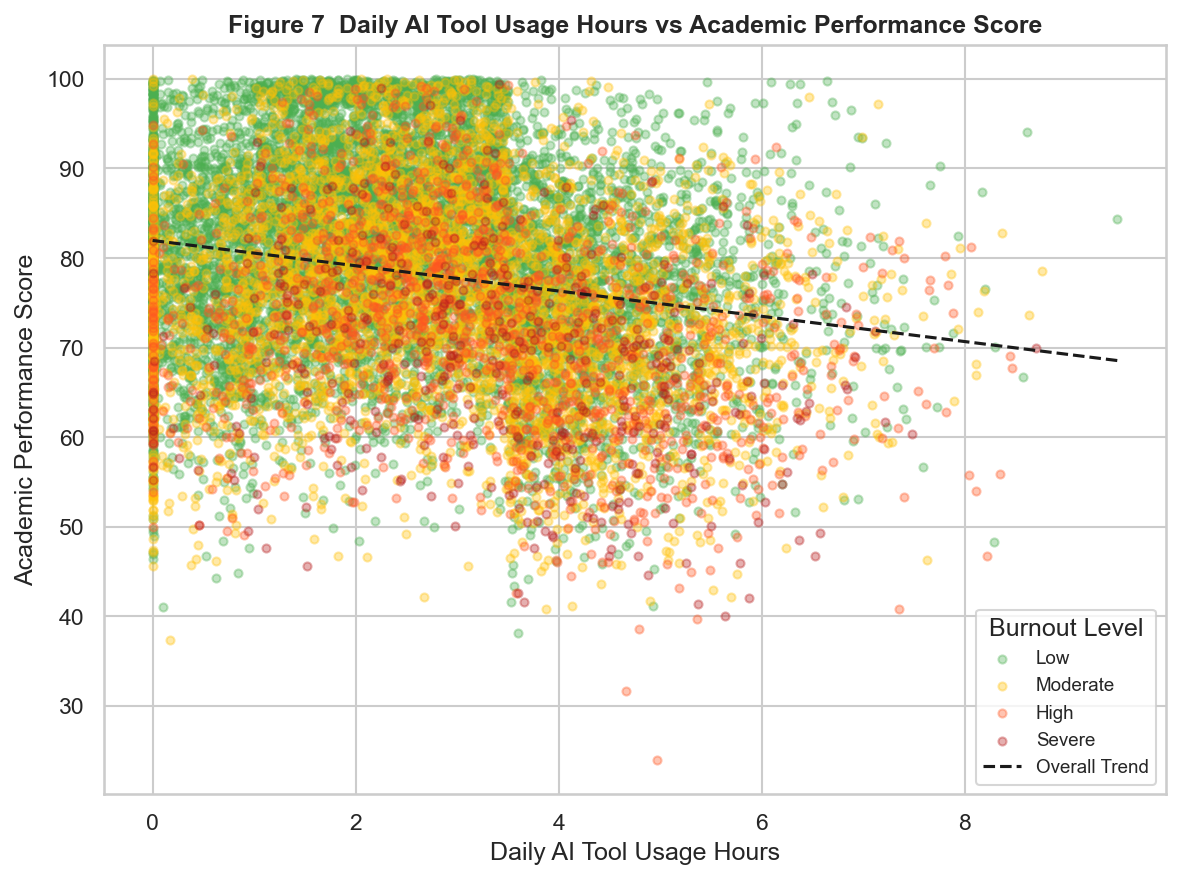

In [11]:
# ============================================================
# Figure 7: Scatter — AI Tool Usage vs Academic Performance
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for lvl in BURNOUT_ORDER:
    sub = df[df["Burnout_Level"] == lvl]
    ax.scatter(
        sub["Daily_AI_Tool_Usage_Hours"], sub["Academic_Performance_Score"],
        label=lvl, alpha=0.35, s=15, color=BURNOUT_PAL[lvl]
    )

# Overall linear trend line
z = np.polyfit(df["Daily_AI_Tool_Usage_Hours"], df["Academic_Performance_Score"], 1)
x_line = np.linspace(df["Daily_AI_Tool_Usage_Hours"].min(),
                     df["Daily_AI_Tool_Usage_Hours"].max(), 100)
ax.plot(x_line, np.poly1d(z)(x_line), "k--", linewidth=1.5, label="Overall Trend")

ax.set_title("Figure 7  Daily AI Tool Usage Hours vs Academic Performance Score",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Daily AI Tool Usage Hours")
ax.set_ylabel("Academic Performance Score")
ax.legend(title="Burnout Level", fontsize=9)
plt.tight_layout()
plt.savefig("fig7_scatter_ai_performance.png", bbox_inches="tight")
plt.show()

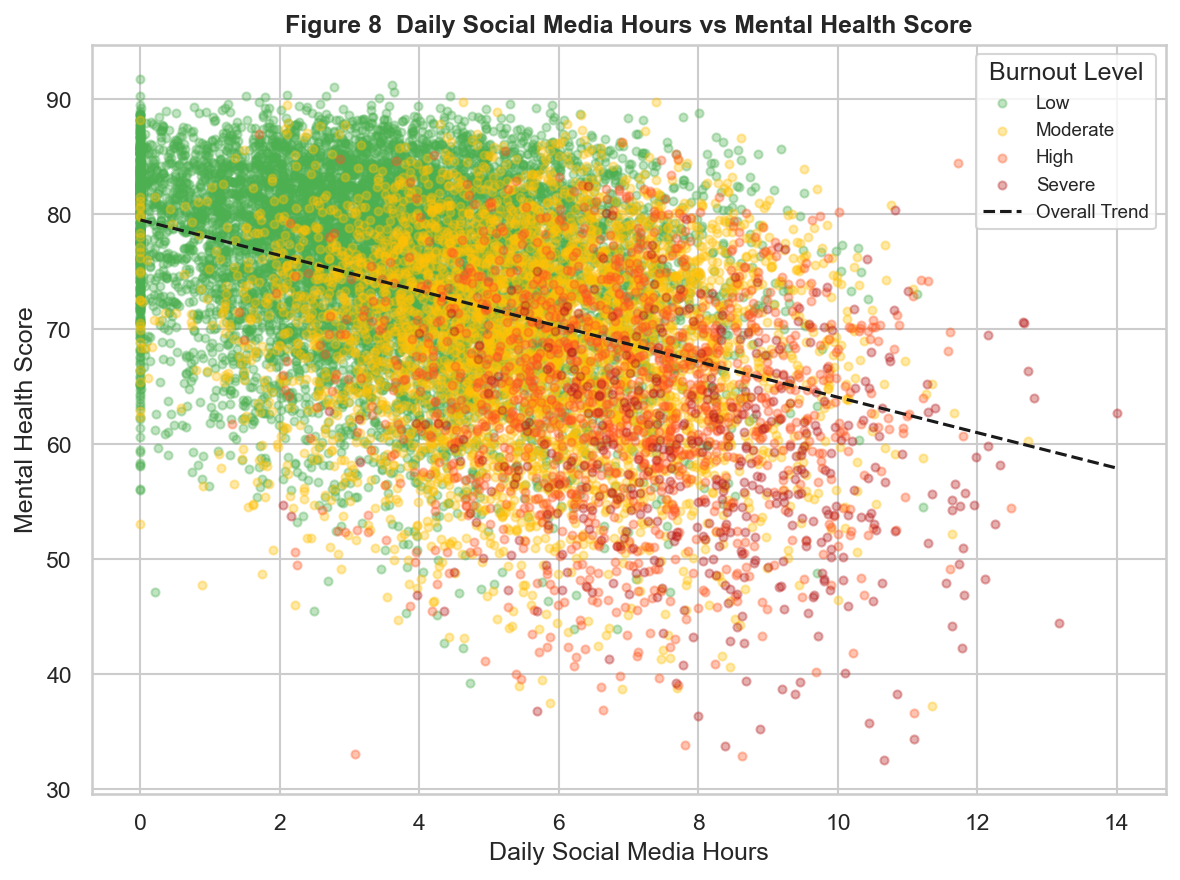

In [12]:
# ============================================================
# Figure 8: Scatter — Social Media Hours vs Mental Health Score
# ============================================================

fig, ax = plt.subplots(figsize=(8, 6))

for lvl in BURNOUT_ORDER:
    sub = df[df["Burnout_Level"] == lvl]
    ax.scatter(
        sub["Daily_Social_Media_Hours"], sub["Mental_Health_Score"],
        label=lvl, alpha=0.35, s=15, color=BURNOUT_PAL[lvl]
    )

z2 = np.polyfit(df["Daily_Social_Media_Hours"], df["Mental_Health_Score"], 1)
x_line2 = np.linspace(df["Daily_Social_Media_Hours"].min(),
                      df["Daily_Social_Media_Hours"].max(), 100)
ax.plot(x_line2, np.poly1d(z2)(x_line2), "k--", linewidth=1.5, label="Overall Trend")

ax.set_title("Figure 8  Daily Social Media Hours vs Mental Health Score",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Daily Social Media Hours")
ax.set_ylabel("Mental Health Score")
ax.legend(title="Burnout Level", fontsize=9)
plt.tight_layout()
plt.savefig("fig8_scatter_socialmedia_mental.png", bbox_inches="tight")
plt.show()

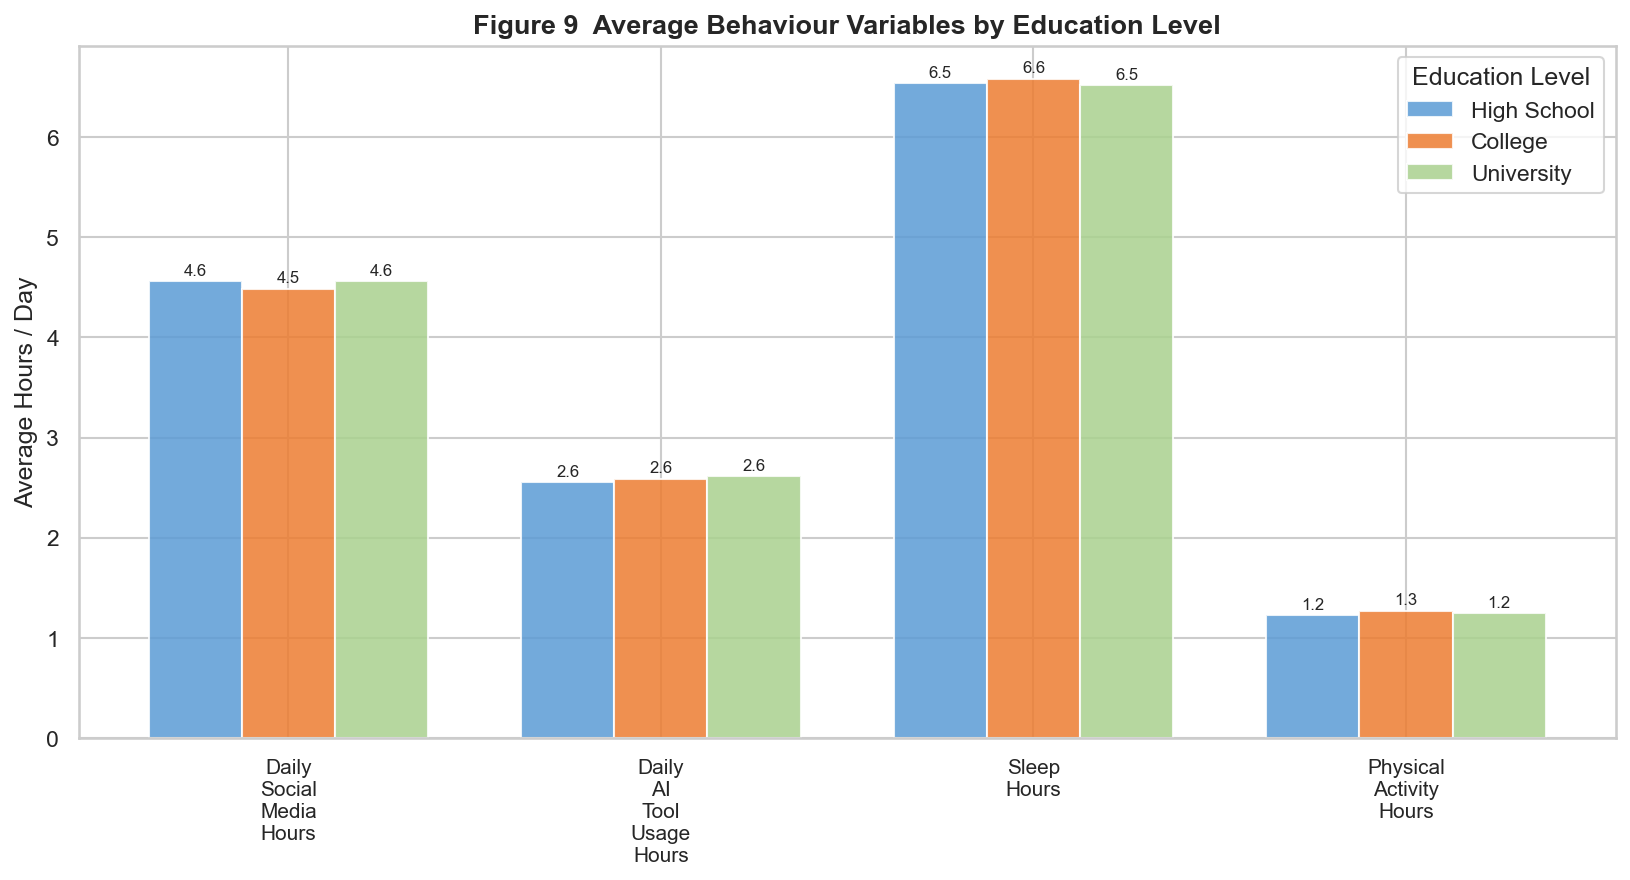

In [13]:
# ============================================================
# Figure 9: Grouped Bar — Behaviour Variables by Education Level
# ============================================================

edu_order = ["High School", "College", "University"]
edu_vars  = ["Daily_Social_Media_Hours", "Daily_AI_Tool_Usage_Hours",
             "Sleep_Hours", "Physical_Activity_Hours"]
edu_means = df.groupby("Education_Level")[edu_vars].mean().reindex(edu_order)

x, width = np.arange(len(edu_vars)), 0.25
edu_colors = ["#5B9BD5", "#ED7D31", "#A9D18E"]

fig, ax = plt.subplots(figsize=(11, 6))
for i, edu in enumerate(edu_order):
    bars = ax.bar(x + i * width, edu_means.loc[edu], width,
                  label=edu, color=edu_colors[i], alpha=0.85, edgecolor="white")
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.03,
                f"{bar.get_height():.1f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x + width)
ax.set_xticklabels([v.replace("_", "\n") for v in edu_vars], fontsize=10)
ax.set_ylabel("Average Hours / Day")
ax.set_title("Figure 9  Average Behaviour Variables by Education Level",
             fontsize=13, fontweight="bold")
ax.legend(title="Education Level")
plt.tight_layout()
plt.savefig("fig9_grouped_bar_education.png", bbox_inches="tight")
plt.show()

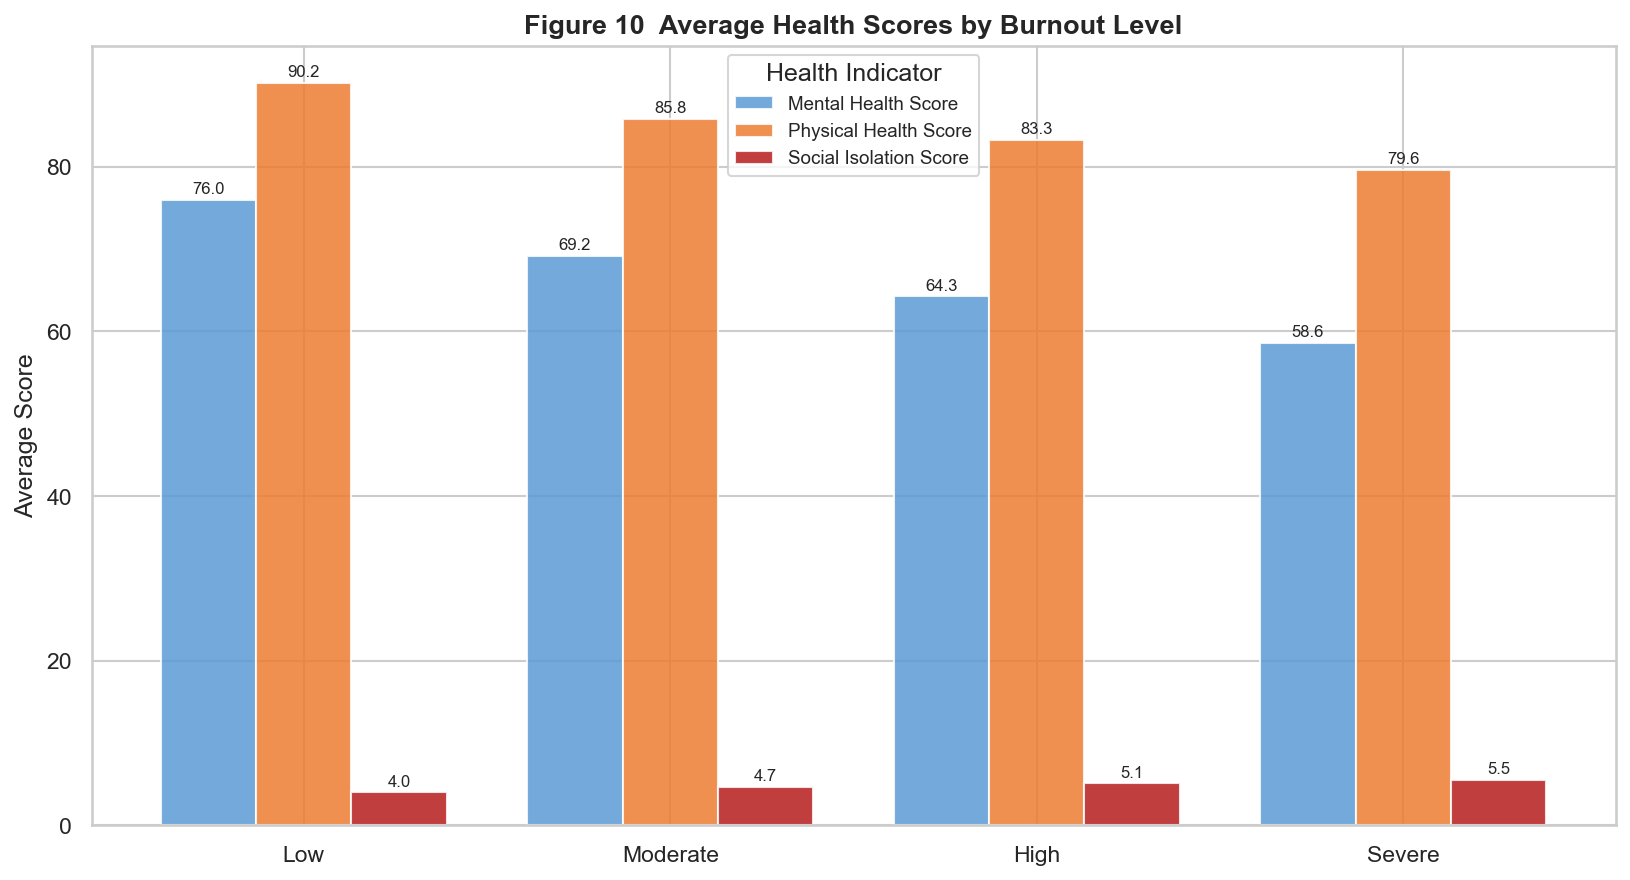

In [14]:
# ============================================================
# Figure 10: Grouped Bar — Health Scores by Burnout Level
# ============================================================

health_vars  = ["Mental_Health_Score", "Physical_Health_Score", "Social_Isolation_Score"]
health_means = df.groupby("Burnout_Level")[health_vars].mean().reindex(BURNOUT_ORDER)

x2, width2  = np.arange(len(BURNOUT_ORDER)), 0.26
h_colors    = ["#5B9BD5", "#ED7D31", "#B71C1C"]

fig, ax = plt.subplots(figsize=(11, 6))
for i, var in enumerate(health_vars):
    bars = ax.bar(x2 + i * width2, health_means[var], width2,
                  label=var.replace("_", " "),
                  color=h_colors[i], alpha=0.85, edgecolor="white")
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.4,
                f"{bar.get_height():.1f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xticks(x2 + width2)
ax.set_xticklabels(BURNOUT_ORDER, fontsize=11)
ax.set_ylabel("Average Score")
ax.set_title("Figure 10  Average Health Scores by Burnout Level",
             fontsize=13, fontweight="bold")
ax.legend(title="Health Indicator", fontsize=9)
plt.tight_layout()
plt.savefig("fig10_health_by_burnout.png", bbox_inches="tight")
plt.show()

In [15]:
# ============================================================
# Section: Key Findings Summary
# ============================================================

print("=" * 60)
print("KEY FINDINGS SUMMARY")
print("=" * 60)

corr_ap = df[NUM_FEATURES + ["Academic_Failure_Risk"]].corr(
    method="pearson")["Academic_Performance_Score"]
print("\nCorrelation with Academic Performance Score (sorted):")
print(corr_ap.drop("Academic_Performance_Score").sort_values().round(3).to_string())

print("\nMean Academic Performance by Burnout Level:")
print(df.groupby("Burnout_Level")["Academic_Performance_Score"]
        .mean().reindex(BURNOUT_ORDER).round(2).to_string())

print("\nMean Sleep Hours by Burnout Level:")
print(df.groupby("Burnout_Level")["Sleep_Hours"]
        .mean().reindex(BURNOUT_ORDER).round(2).to_string())

KEY FINDINGS SUMMARY

Correlation with Academic Performance Score (sorted):
Daily_Social_Media_Hours    -0.394
Academic_Failure_Risk       -0.296
Social_Isolation_Score      -0.235
Daily_AI_Tool_Usage_Hours   -0.205
Age                         -0.008
Physical_Activity_Hours      0.042
Physical_Health_Score        0.151
Mental_Health_Score          0.204
Sleep_Hours                  0.292

Mean Academic Performance by Burnout Level:
Burnout_Level
Low         80.86
Moderate    75.79
High        72.44
Severe      68.64

Mean Sleep Hours by Burnout Level:
Burnout_Level
Low         6.91
Moderate    6.17
High        5.67
Severe      5.24
